# 04 · Modelos econométricos espaciales del acceso financiero

| | |
|---|---|
| **Objetivo** | Estimar el efecto de la pobreza, la urbanización, la altitud y la densidad poblacional sobre el acceso a canales financieros, controlando la dependencia espacial detectada en el notebook 03 (I de Moran = 0,28). |
| **Especificación** | y = √acceso_eb; matriz de contigüidad Reina estandarizada por filas. |
| **Modelos** | OLS con diagnóstico LM (Anselin, 1988); SAR y SEM por máxima verosimilitud; S2SLS y GMM heterocedástico (Kelejian y Prucha, 1998, 2010); modelo espacial de Durbin con descomposición de impactos (LeSage y Pace, 2009). |
| **Salidas** | `outputs/figuras/04_*.png` · `outputs/tablas/04_comparacion_modelos.csv`. |

In [1]:
from pathlib import Path
import warnings

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import spreg
from esda import Moran
from libpysal import weights

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "processed"
FIG = ROOT / "outputs" / "figuras"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
print("spreg", spreg.__version__)

spreg 1.9.0


## 1. Datos y variables

In [2]:
g = gpd.read_file(DATA / "geobanca_norte.gpkg", layer="distritos").to_crs("EPSG:32717")
lisa = pd.read_csv(DATA / "lisa_acceso.csv", dtype={"ubigeo": str})[["ubigeo", "y", "pobreza_imp", "lisa"]]
g = g.merge(lisa, on="ubigeo").reset_index(drop=True)

# Covariables (faltantes de Alto Trujillo: pobreza imputada por rezago espacial en el notebook 03; altitud con la media)
g["altitud_km"] = g["altitud_capital_m"].fillna(g["altitud_capital_m"].mean()) / 1000
g["log_densidad"] = np.log(g["densidad_hab_km2"])

Y_NAME = "y"
X_NAMES = ["pobreza_imp", "pct_urbana", "altitud_km", "log_densidad"]
ETIQUETAS = {"CONSTANT": "Constante", "pobreza_imp": "Pobreza 2018 (%)", "pct_urbana": "Población urbana (%)",
             "altitud_km": "Altitud (km)", "log_densidad": "log densidad (hab/km²)",
             "W_y": "rho (rezago de y)", "lambda": "lambda (error espacial)"}

y = g[[Y_NAME]].to_numpy()
X = g[X_NAMES].to_numpy()
w = weights.Queen.from_dataframe(g, use_index=False)
w.transform = "r"
g[[Y_NAME] + X_NAMES].describe().round(2)

,y,pobreza_imp,pct_urbana,altitud_km,log_densidad
count,327.00,327.00,327.00,327.00,327.00
mean,10.28,43.12,37.41,1.45,3.90
std,3.64,19.77,40.67,1.21,1.46
min,2.59,4.99,0.00,0.00,-0.02
25%,7.70,25.80,0.00,0.08,3.04
50%,10.18,45.33,20.69,1.56,3.59
75%,12.76,59.53,83.27,2.62,4.47
max,23.31,81.00,100.00,3.99,10.04


## 2. Multicolinealidad

Pobreza e IDH miden casi lo mismo (notebook 02), por eso se incluye solo pobreza. Se revisan los factores de
inflación de varianza (VIF): valores mayores a 5 o 10 indicarían colinealidad problemática.

In [3]:
def vif(df):
    Z = (df - df.mean()) / df.std()
    R = np.corrcoef(Z.T)
    return pd.Series(np.diag(np.linalg.inv(R)), index=df.columns, name="VIF")
vif(g[X_NAMES]).round(2)

pobreza_imp     3.47
pct_urbana      3.98
altitud_km      2.73
log_densidad    1.60
Name: VIF, dtype: float64

## 3. Modelo lineal clásico (OLS) y diagnóstico espacial

Si los residuos del OLS están autocorrelacionados, sus errores estándar son inválidos. Las pruebas de
multiplicadores de Lagrange (LM) indican qué estructura espacial falta:

- **LM-rezago / LM-rezago robusto:** dependencia en la variable respuesta (modelo SAR).
- **LM-error / LM-error robusto:** dependencia en el término de error (modelo SEM).

Regla de decisión de Anselin (2005): si ambas LM simples son significativas, se comparan las versiones robustas.

In [4]:
ols = spreg.OLS(y, X, w=w, spat_diag=True, moran=True, white_test=True,
                name_y=Y_NAME, name_x=X_NAMES, name_w="Reina", name_ds="GeoBanca Norte")
print(ols.summary)

REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: ORDINARY LEAST SQUARES
------------------------------------------------------------------------------------
Data set            :GeoBanca Norte
Weights matrix      :       Reina
Dependent Variable  :           y                Number of Observations:         327
Mean dependent var  :     10.2784                Number of Variables   :           5
S.D. dependent var  :      3.6434                Degrees of Freedom    :         322
R-squared           :      0.2334
Adjusted R-squared  :      0.2239
Sum squared residual:     3317.46                F-statistic           :     24.5075
Sigma-square        :      10.303                Prob(F-statistic)     :   1.007e-17
S.E. of regression  :       3.210                Log likelihood        :    -842.822
Sigma-square ML     :      10.145                Akaike info criterion :    1695.643
S.E of regression ML:      3.1851                Schwarz criterion     :    1714.593

---------------

In [5]:
diag = pd.DataFrame({
    "estadístico": [ols.moran_res[0], ols.lm_lag[0], ols.rlm_lag[0], ols.lm_error[0], ols.rlm_error[0], ols.jarque_bera["jb"], ols.breusch_pagan["bp"]],
    "p-valor": [ols.moran_res[2], ols.lm_lag[1], ols.rlm_lag[1], ols.lm_error[1], ols.rlm_error[1], ols.jarque_bera["pvalue"], ols.breusch_pagan["pvalue"]],
}, index=["I de Moran (residuos)", "LM rezago", "LM rezago robusto", "LM error", "LM error robusto",
          "Jarque-Bera (normalidad)", "Breusch-Pagan (heterocedasticidad)"])
diag.round(4)

,estadístico,p-valor
I de Moran (residuos),0.2144,0.0000
LM rezago,21.6376,0.0000
LM rezago robusto,15.3055,0.0001
LM error,37.6966,0.0000
LM error robusto,31.3645,0.0000
Jarque-Bera (normalidad),6.5351,0.0381
Breusch-Pagan (heterocedasticidad),3.2686,0.5139


## 4. Modelos espaciales por máxima verosimilitud (ML)

- **SAR (rezago espacial):** `y = ρWy + Xβ + ε`. El acceso de un distrito depende del acceso de sus vecinos
  (derrame: un agente atiende también a gente del distrito vecino).
- **SEM (error espacial):** `y = Xβ + u,  u = λWu + ε`. La dependencia viene de factores no observados con
  estructura espacial (geografía, vías, mercados).

In [6]:
sar = spreg.ML_Lag(y, X, w=w, name_y=Y_NAME, name_x=X_NAMES, name_w="Reina")
sem = spreg.ML_Error(y, X, w=w, name_y=Y_NAME, name_x=X_NAMES, name_w="Reina")
print(sar.summary)
print(sem.summary)

ML_Lag
ML_Error
REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :       Reina
Dependent Variable  :           y                Number of Observations:         327
Mean dependent var  :     10.2784                Number of Variables   :           6
S.D. dependent var  :      3.6434                Degrees of Freedom    :         321
Pseudo R-squared    :      0.2864
Spatial Pseudo R-squared:  0.2104
Log likelihood      :   -834.1708
Sigma-square ML     :      9.4532                Akaike info criterion :    1680.342
S.E of regression   :      3.0746                Schwarz criterion     :    1703.081

------------------------------------------------------------------------------------
            Variable     Coefficient       Std.Error     z-Statistic     Probability
----------------------------

## 5. Estimación por GMM / variables instrumentales

La estimación ML supone errores normales y homocedásticos; Jarque-Bera y Breusch-Pagan rechazan esos supuestos
(sección 3). Los estimadores GMM de Kelejian y Prucha son robustos a no normalidad y, en su versión `Het`,
a heterocedasticidad. Si los coeficientes coinciden con los de ML, las conclusiones son confiables.

In [7]:
sar_gmm = spreg.GM_Lag(y, X, w=w, w_lags=2, robust="white", name_y=Y_NAME, name_x=X_NAMES, name_w="Reina")
sem_gmm = spreg.GM_Error_Het(y, X, w=w, name_y=Y_NAME, name_x=X_NAMES, name_w="Reina")
print(sar_gmm.summary)
print(sem_gmm.summary)

GM_Lag
GM_Error_Het
REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: SPATIAL TWO STAGE LEAST SQUARES
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :       Reina
Dependent Variable  :           y                Number of Observations:         327
Mean dependent var  :     10.2784                Number of Variables   :           6
S.D. dependent var  :      3.6434                Degrees of Freedom    :         321
Pseudo R-squared    :      0.0676
Spatial Pseudo R-squared:  0.2656

White Standard Errors
------------------------------------------------------------------------------------
            Variable     Coefficient       Std.Error     z-Statistic     Probability
------------------------------------------------------------------------------------
            CONSTANT        19.54775         2.96614         6.59030         0.00000
         pobreza_imp        -0.04309         0.0201

**Nota sobre el SAR por GMM.** El estimador S2SLS usa como instrumentos los rezagos de las covariables (WX) y
da un ρ negativo, opuesto al de ML. No es un problema de instrumentos débiles (el estadístico F de la primera
etapa es 14,5): ocurre porque WX **no cumple la restricción de exclusión**, es decir, las covariables de los
vecinos afectan directamente al acceso del distrito. Eso es justamente lo que modela el SDM de la sección
siguiente, y es una señal de que el SAR puro está mal especificado.

## 6. Extra: modelo espacial de Durbin (SDM) e impactos

El SDM agrega el rezago de las covariables (`WX`): `y = ρWy + Xβ + WXθ + ε`. En modelos con `ρ`, los
coeficientes no son efectos marginales; se reportan los **impactos directos** (en el propio distrito),
**indirectos** (derrame hacia los vecinos) y **totales** (LeSage y Pace, 2009).

In [8]:
sdm = spreg.ML_Lag(y, X, w=w, slx_lags=1, spat_impacts="simple",
                   name_y=Y_NAME, name_x=X_NAMES, name_w="Reina")
print(sdm.summary)

ML_Lag
REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG WITH SLX - SPATIAL DURBIN MODEL (METHOD = FULL)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :       Reina
Dependent Variable  :           y                Number of Observations:         327
Mean dependent var  :     10.2784                Number of Variables   :          10
S.D. dependent var  :      3.6434                Degrees of Freedom    :         317
Pseudo R-squared    :      0.3836
Spatial Pseudo R-squared:  0.2760
Log likelihood      :   -814.0206
Sigma-square ML     :      8.1849                Akaike info criterion :    1648.041
S.E of regression   :      2.8609                Schwarz criterion     :    1685.941

------------------------------------------------------------------------------------
            Variable     Coefficient       Std.Error     z-Statistic     Probability
-----

## 7. Comparación de modelos

In [9]:
def fila(m, nombre, metodo):
    r = {"modelo": nombre, "método": metodo}
    nombres = list(m.name_x)
    for k, nm in enumerate(nombres):
        if nm in ETIQUETAS or nm in X_NAMES:
            p = m.z_stat[k][1] if hasattr(m, "z_stat") else m.t_stat[k][1]
            est = "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.1 else ""
            r[ETIQUETAS.get(nm, nm)] = f"{m.betas[k][0]:.3f}{est}"
    for atr, et in [("rho", "rho (rezago de y)"), ("lam", "lambda (error espacial)")]:
        if hasattr(m, atr) and not isinstance(getattr(m, atr), (list, type(None))):
            r[et] = f"{float(np.ravel(getattr(m, atr))[0]):.3f}"
    r["log-verosimilitud"] = round(float(m.logll), 1) if hasattr(m, "logll") else ""
    r["AIC"] = round(float(m.aic), 1) if hasattr(m, "aic") else ""
    r["pseudo R²"] = round(float(getattr(m, "pr2", getattr(m, "r2", np.nan))), 3)
    res = m.e_filtered if hasattr(m, "e_filtered") else m.u
    r["I de Moran residuos"] = round(Moran(res.flatten(), w, permutations=999).I, 3)
    return r

tabla = pd.DataFrame([fila(ols, "OLS", "MCO"), fila(sar, "SAR", "ML"), fila(sem, "SEM", "ML"),
                      fila(sar_gmm, "SAR", "GMM/2SLS robusto"), fila(sem_gmm, "SEM", "GMM Het"), fila(sdm, "SDM", "ML")]).set_index(["modelo", "método"])
tabla = tabla.fillna("")
tabla.to_csv(ROOT / "outputs" / "tablas" / "04_comparacion_modelos.csv")
tabla.T

modelo,OLS,SAR,SEM,SAR,SEM,SDM
método,MCO,ML,ML,GMM/2SLS robusto,GMM Het,ML
Constante,12.217***,8.690***,12.146***,19.548***,12.143***,8.876***
Pobreza 2018 (%),-0.041**,-0.040**,-0.057***,-0.043**,-0.054***,-0.067***
Población urbana (%),0.022**,0.021**,0.027***,0.024*,0.026**,0.029***
Altitud (km),-0.266,0.000,-0.124,-0.819***,-0.127,-0.955**
log densidad (hab/km²),-0.152,-0.148,-0.092,-0.160,-0.104,0.220
log-verosimilitud,-842.8,-834.2,-825.8,,,-814.0
AIC,1695.6,1680.3,1661.7,,,1648.0
pseudo R²,0.233,0.286,0.231,0.068,0.232,0.384
I de Moran residuos,0.214,0.045,-0.016,0.511,-0.008,0.001


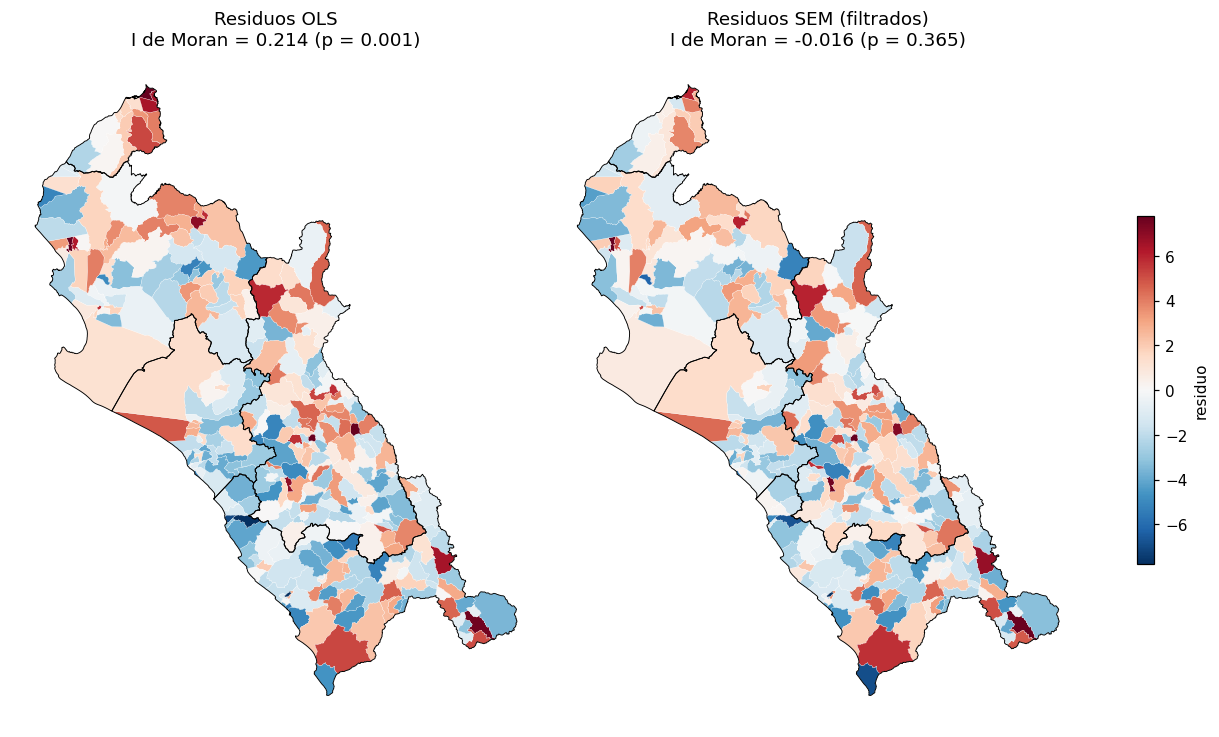

In [10]:
# Residuos: OLS vs SEM
g["res_ols"] = ols.u.flatten()
g["res_sem"] = sem.e_filtered.flatten()
vmax = np.abs(g[["res_ols", "res_sem"]]).quantile(0.98).max()
deps = g.dissolve("departamento").reset_index()

fig, axes = plt.subplots(1, 2, figsize=(11, 6.8), constrained_layout=True)
for ax, col, titulo in [(axes[0], "res_ols", "Residuos OLS"), (axes[1], "res_sem", "Residuos SEM (filtrados)")]:
    mi = Moran(g[col], w, permutations=999)
    g.plot(column=col, cmap="RdBu_r", vmin=-vmax, vmax=vmax, ax=ax, edgecolor="white", linewidth=0.15)
    deps.boundary.plot(ax=ax, color="black", linewidth=0.6)
    ax.set_title(f"{titulo}\nI de Moran = {mi.I:.3f} (p = {mi.p_sim:.3f})")
    ax.set_axis_off()
sm = plt.cm.ScalarMappable(cmap="RdBu_r", norm=plt.Normalize(-vmax, vmax))
fig.colorbar(sm, ax=axes, shrink=0.5, label="residuo")
fig.savefig(FIG / "04_residuos_ols_sem.png", bbox_inches="tight")
plt.show()

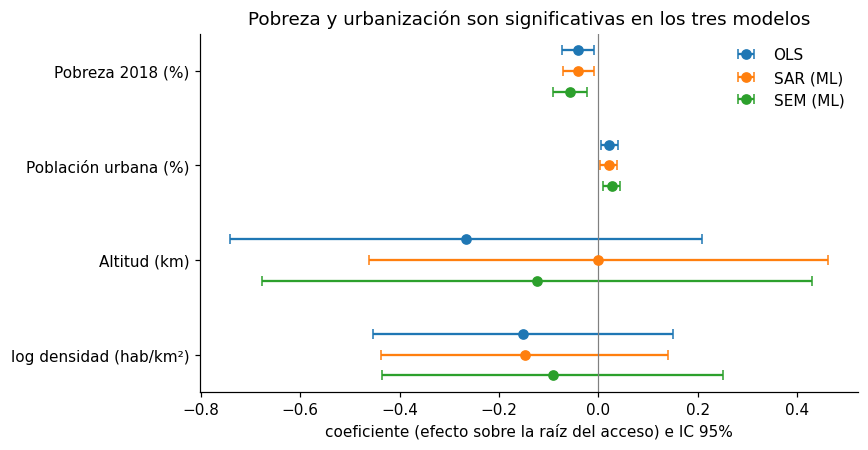

In [11]:
# Coeficientes con intervalos al 95%: OLS vs SAR vs SEM (ML)
modelos = {"OLS": (ols, "t_stat"), "SAR (ML)": (sar, "z_stat"), "SEM (ML)": (sem, "z_stat")}
fig, ax = plt.subplots(figsize=(8, 4.2))
for k, (nombre, (m, _)) in enumerate(modelos.items()):
    nx = list(m.name_x)
    idx = [nx.index(v) for v in X_NAMES]
    b = m.betas.flatten()[idx]
    se = m.std_err[idx]
    pos = np.arange(len(X_NAMES)) + (k - 1) * 0.22
    ax.errorbar(b, pos, xerr=1.96 * se, fmt="o", capsize=3, label=nombre)
ax.axvline(0, color="grey", linewidth=0.8)
ax.set_yticks(np.arange(len(X_NAMES)), [ETIQUETAS[v] for v in X_NAMES])
ax.invert_yaxis()
ax.set_xlabel("coeficiente (efecto sobre la raíz del acceso) e IC 95%")
ax.legend(frameon=False)
ax.set_title("Pobreza y urbanización son significativas en los tres modelos")
fig.tight_layout()
fig.savefig(FIG / "04_coeficientes.png", bbox_inches="tight")
plt.show()

## 8. Hallazgos para el proyecto

1. **El OLS no sirve como modelo final.** Explica 23% de la varianza, pero sus residuos tienen I de Moran = 0,21
   (p < 0,001): los errores estándar no son válidos.
2. **Las pruebas LM apuntan al error espacial.** Las dos versiones robustas son significativas, pero LM-error
   robusto (31,4) supera a LM-rezago robusto (15,3). El **SEM** baja el AIC de 1696 a 1662 y deja residuos sin
   autocorrelación (I = -0,02). El λ = 0,45 indica factores no observados con estructura espacial (vías,
   geografía, dinámica de mercados).
3. **Los efectos son robustos a la especificación.** En OLS, SAR, SEM (ML y GMM) y SDM, la pobreza reduce el
   acceso y la urbanización lo aumenta, siempre con p < 0,05. Con el SEM por ML, 10 puntos más de pobreza
   restan 0,57 a la raíz del acceso, alrededor de 11 puntos de atención por 10 mil adultos en la mediana.
4. **El mejor ajuste es el modelo de Durbin (SDM, AIC 1648).** La prueba de factor común rechaza la restricción
   que llevaría al SEM (p = 0,0004). La urbanización tiene un efecto directo positivo y un **derrame negativo**:
   una ciudad grande concentra la oferta y deja con menos acceso a los distritos vecinos. La altitud solo
   aparece significativa al controlar los rezagos (efecto directo -0,96 por km).
5. **Para el póster** se reportan OLS, SEM y SDM (tabla `outputs/tablas/04_comparacion_modelos.csv`) y el
   mapa de residuos OLS frente a SEM como figura del objetivo 2.